# 统计学习导论作业 1：加州房价回归

**主题：** 多种线性回归方法的训练、调参、验证与测试  
**姓名：** 咸蛋超人迪卡　**班级：** 统计　**学号：** 114514

## 一、研究问题与数据

本作业使用 scikit-learn 整理的 California Housing 数据集，观察 1990 年美国加州人口普查街区特征与房屋中位数之间的预测关系。数据有 20,640 个街区样本和 8 个输入特征，目标 `MedHouseVal` 是房屋中位数，单位为 **10 万美元**。例如目标值 2.0 表示约 20 万美元。

特征包括街区收入中位数、房龄、房间数、卧室数、人口、家庭数及经纬度。房间数、人口和家庭数是街区总量，受街区规模影响；它们与目标之间的相关性不能直接解释为因果关系。目标在数据中存在上限截断，极高房价街区的真实差异未必完全反映在目标值上。

本作业以 OLS 为基线，比较 Ridge、Lasso、Elastic Net、LARS、LassoLars 和 SGDRegressor。比较重点是正则化、稀疏系数和优化方法对验证表现与泛化误差的影响。

## 二、导入工具、载入数据与初步核对

先核对样本规模、缺失值和量纲，再查看摘要统计。房屋价值是连续变量，因此使用回归指标，而不是分类准确率。

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, Lars, LassoLars, SGDRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", category=FutureWarning)

# 从仓库中的本地 CSV 读数，保证离线可复现。
data_path = Path("../data/california_housing.csv")
housing = pd.read_csv(data_path)
target_name = "MedHouseVal"
X = housing.drop(columns=target_name)
y = housing[target_name]

print(f"数据规模：{housing.shape[0]:,} 行 × {housing.shape[1]} 列")
print("缺失值总数：", int(housing.isna().sum().sum()))
print("目标单位：10 万美元；目标范围：", (round(y.min(), 2), round(y.max(), 2)))
display(housing.head(8))
display(housing.describe().T.round(3))

数据规模：20,640 行 × 9 列
缺失值总数： 0
目标单位：10 万美元；目标范围： (np.float64(0.15), np.float64(5.0))


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


### 2.1 数据分布与特征关系

目标分布用于观察偏态和上限堆积；地理散点图展示房价与地理位置的共同变化；相关系数热图仅描述两两线性相关，不能替代因果分析。

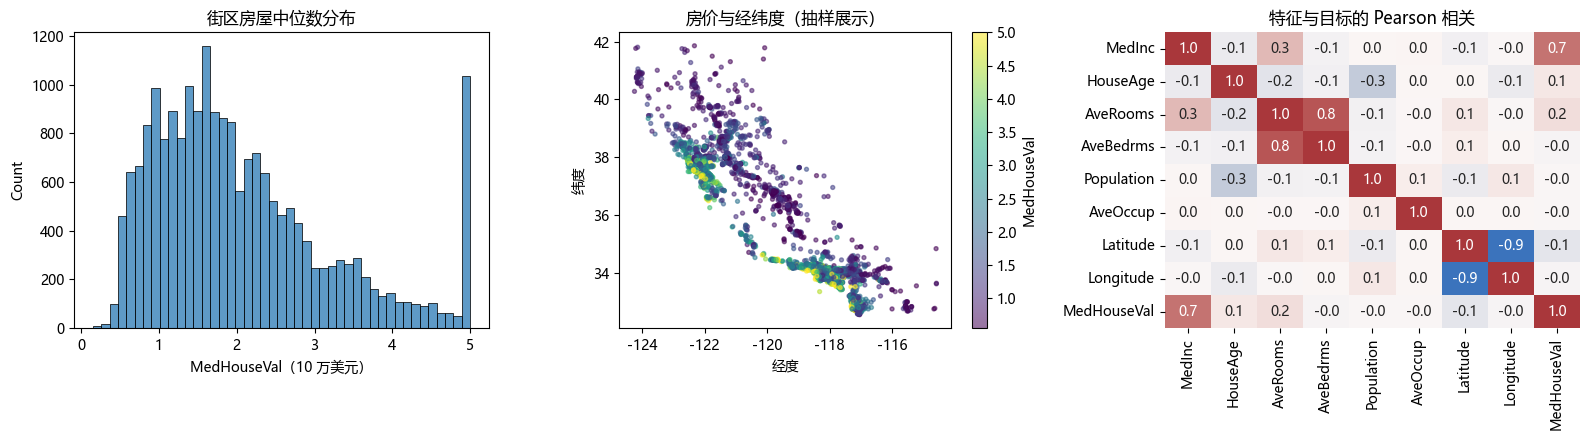

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(y, bins=45, ax=axes[0], color="#2878B5")
axes[0].set(title="街区房屋中位数分布", xlabel="MedHouseVal（10 万美元）")

# 为了让地理分布图易读，对大样本做固定随机种子的可视化抽样；建模仍使用全部样本。
geo_sample = housing.sample(n=5000, random_state=42)
points = axes[1].scatter(geo_sample["Longitude"], geo_sample["Latitude"],
                         c=geo_sample[target_name], s=8, alpha=0.55,
                         cmap="viridis", vmin=y.quantile(0.02), vmax=y.quantile(0.98))
axes[1].set(title="房价与经纬度（抽样展示）", xlabel="经度", ylabel="纬度")
fig.colorbar(points, ax=axes[1], label="MedHouseVal")

sns.heatmap(housing.corr(numeric_only=True), cmap="vlag", center=0,
            annot=True, fmt=".1f", ax=axes[2], cbar=False)
axes[2].set_title("特征与目标的 Pearson 相关")
plt.tight_layout()
plt.show()

## 三、训练集、验证集和测试集

先留出 20% 测试集，再从其余 80% 留出四分之一作为验证集，最终比例约为 **训练 60% / 验证 20% / 测试 20%**。训练集用于交叉验证调参；验证集用于在不同模型族之间选模；测试集只在选定模型并用训练+验证数据重拟合后评估一次。

目标值按十分位分箱后用于分层抽样，让三个子集的房价区间构成接近。分箱只服务于抽样，不作为模型特征。交叉验证在训练集内打乱分折，固定随机种子以便复现。

In [3]:
# 用目标值分位箱近似分层抽样，避免某个子集缺少高/低价区间。
price_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=price_bins
)
train_val_bins = pd.qcut(y_train_val, q=10, labels=False, duplicates="drop")
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25,
    random_state=42, stratify=train_val_bins
)
cv = KFold(n_splits=3, shuffle=True, random_state=42)
print(f"训练集：{len(X_train):,} ({len(X_train)/len(X):.0%})")
print(f"验证集：{len(X_val):,} ({len(X_val)/len(X):.0%})")
print(f"测试集：{len(X_test):,} ({len(X_test)/len(X):.0%})")
display(pd.DataFrame({
    "训练集": y_train.describe(), "验证集": y_val.describe(), "测试集": y_test.describe()
}).round(3))

训练集：12,384 (60%)
验证集：4,128 (20%)
测试集：4,128 (20%)


,训练集,验证集,测试集
count,12384.000,4128.000,4128.000
mean,2.069,2.070,2.065
std,1.154,1.158,1.149
min,0.150,0.225,0.150
25%,1.197,1.193,1.199
50%,1.797,1.797,1.796
75%,2.645,2.660,2.649
max,5.000,5.000,5.000


## 四、回归模型与调参

### 4.1 模型思路

- **OLS：** 最小化残差平方和，提供不带惩罚的线性基准。
- **Ridge：** 在平方误差上增加 $\alpha\sum_j\beta_j^2$，连续收缩系数，适合相关特征较多的情形。
- **Lasso：** 增加 $\alpha\sum_j|\beta_j|$，可把部分系数压为零，实现稀疏化。
- **Elastic Net：** 混合 L1 与 L2 惩罚；`l1_ratio` 越大，Lasso 成分越强。
- **LARS：** 最小角度回归沿着与当前残差最相关的方向逐步加入变量；`n_nonzero_coefs` 控制路径上的模型规模。
- **LassoLars：** 用 LARS 路径求解 Lasso，`alpha` 控制稀疏惩罚。
- **SGDRegressor：** 通过随机梯度下降近似优化线性回归目标，学习率、正则化和迭代停止条件会影响收敛。

除 OLS 外，所有模型都在 Pipeline 中标准化。标准化器在每一个交叉验证训练折内拟合，避免验证折信息泄漏。每个模型的参数由训练集三折交叉验证上的 RMSE 搜索；模型族随后根据独立验证集 RMSE 排序。测试集不参与任何调参。

### 4.2 评估指标

主指标为 **RMSE**，单位仍是 10 万美元，对较大的误差惩罚更重。**MAE** 是典型绝对误差，较少受个别极端值影响；**$R^2$** 表示相对预测均值基线解释的目标变异比例。此数据目标严格为正，但低价街区的分母很小，MAPE 会过度放大低价样本误差，因此不作为主指标。

In [4]:
models = {
    "OLS": (Pipeline([("model", LinearRegression())]), {}),
    "Ridge": (
        Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
        {"model__alpha": np.logspace(-3, 3, 13)},
    ),
    "Lasso": (
        Pipeline([("scale", StandardScaler()),
                  ("model", Lasso(max_iter=20000, tol=1e-4))]),
        {"model__alpha": np.logspace(-4, 0, 13)},
    ),
    "Elastic Net": (
        Pipeline([("scale", StandardScaler()),
                  ("model", ElasticNet(max_iter=20000, tol=1e-4))]),
        {"model__alpha": np.logspace(-4, 0, 9),
         "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    ),
    "LARS": (
        Pipeline([("scale", StandardScaler()), ("model", Lars())]),
        {"model__n_nonzero_coefs": [2, 3, 4, 5, 6, 7, 8]},
    ),
    "LassoLars": (
        Pipeline([("scale", StandardScaler()), ("model", LassoLars(max_iter=5000))]),
        {"model__alpha": np.logspace(-4, -0.5, 12)},
    ),
    "SGD": (
        Pipeline([("scale", StandardScaler()),
                  ("model", SGDRegressor(max_iter=5000, tol=1e-4,
                                          early_stopping=True, random_state=42))]),
        {"model__loss": ["squared_error", "huber"],
         "model__penalty": ["l2", "elasticnet"],
         "model__alpha": [1e-5, 1e-4, 1e-3],
         "model__learning_rate": ["optimal", "adaptive"]},
    ),
    "均值基准": (Pipeline([("model", DummyRegressor(strategy="mean"))]), {}),
}

searches, fitted_train, rows = {}, {}, []
for name, (pipeline, param_grid) in models.items():
    if param_grid:
        search = GridSearchCV(
            pipeline, param_grid, scoring="neg_root_mean_squared_error",
            cv=cv, n_jobs=1, return_train_score=True,
        )
        search.fit(X_train, y_train)
        estimator = search.best_estimator_
        cv_rmse = -search.best_score_
        best_params = search.best_params_
        searches[name] = search
    else:
        estimator = pipeline.fit(X_train, y_train)
        cv_rmse = -cross_val_score(
            pipeline, X_train, y_train,
            scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1,
        ).mean()
        best_params = "无（基准模型）"
    fitted_train[name] = estimator
    train_pred = estimator.predict(X_train)
    val_pred = estimator.predict(X_val)
    rows.append({
        "模型": name,
        "CV RMSE": cv_rmse,
        "训练 RMSE": mean_squared_error(y_train, train_pred) ** 0.5,
        "验证 RMSE": mean_squared_error(y_val, val_pred) ** 0.5,
        "验证 MAE": mean_absolute_error(y_val, val_pred),
        "验证 R²": r2_score(y_val, val_pred),
        "最优参数": best_params,
    })

validation_results = pd.DataFrame(rows).sort_values("验证 RMSE").reset_index(drop=True)
display(validation_results.round(4))

,模型,CV RMSE,训练 RMSE,验证 RMSE,验证 MAE,验证 R²,最优参数
0,LARS,0.7184,0.7171,0.7300,0.5320,0.6027,{'model__n_nonzero_coefs': 7}
1,Lasso,0.7184,0.7170,0.7301,0.5320,0.6025,{'model__alpha': 0.001}
2,Elastic Net,0.7184,0.7170,0.7301,0.5320,0.6025,"{'model__alpha': 0.001, 'model__l1_ratio': 0.9}"
3,LassoLars,0.7184,0.7170,0.7301,0.5320,0.6025,{'model__alpha': 0.0009006280202112786}
4,Ridge,0.7185,0.7170,0.7303,0.5319,0.6023,{'model__alpha': 3.1622776601683795}
5,OLS,0.7185,0.7170,0.7303,0.5320,0.6023,无（基准模型）
6,SGD,0.9756,0.9598,0.8011,0.5096,0.5214,"{'model__alpha': 0.001, 'model__learning_rate'..."
7,均值基准,1.1546,1.1543,1.1580,0.9153,-0.0000,无（基准模型）


### 4.3 调参过程：以 Ridge 为例

Ridge 的 `alpha` 从 $10^{-3}$ 到 $10^3$ 按对数间隔取值。小惩罚下训练误差通常较低；惩罚逐渐增强时系数收缩，验证误差可能先下降再上升。曲线最低点对应当前搜索范围中泛化表现较好的惩罚强度。若训练误差持续降低、验证误差上升，则是过拟合信号；若两者都很高，模型可能过度受限。

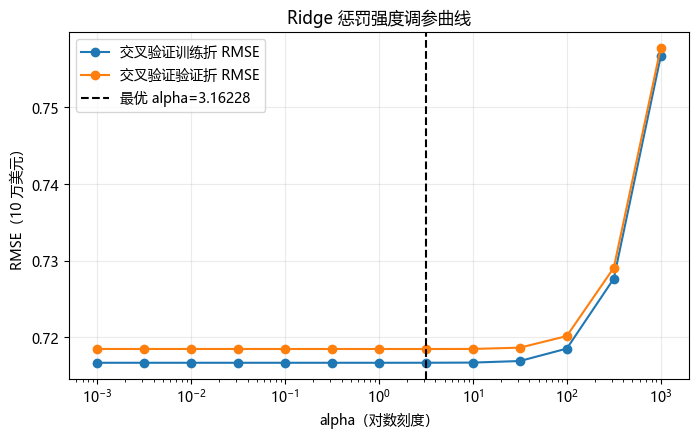

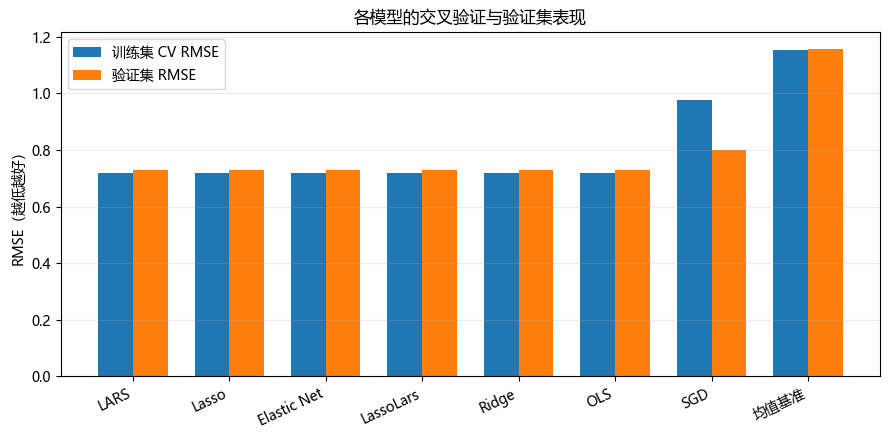

In [5]:
ridge_cv = pd.DataFrame(searches["Ridge"].cv_results_)
alphas = ridge_cv["param_model__alpha"].astype(float)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(alphas, -ridge_cv["mean_train_score"], marker="o", label="交叉验证训练折 RMSE")
ax.semilogx(alphas, -ridge_cv["mean_test_score"], marker="o", label="交叉验证验证折 RMSE")
best_alpha = searches["Ridge"].best_params_["model__alpha"]
ax.axvline(best_alpha, color="black", linestyle="--", label=f"最优 alpha={best_alpha:g}")
ax.set(xlabel="alpha（对数刻度）", ylabel="RMSE（10 万美元）", title="Ridge 惩罚强度调参曲线")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

# 同时查看调参候选下 CV 最优值与独立验证误差；两者排序不完全一致是正常的抽样波动。
fig, ax = plt.subplots(figsize=(9, 4.5))
ordered = validation_results.sort_values("验证 RMSE")
positions = np.arange(len(ordered))
ax.bar(positions - 0.18, ordered["CV RMSE"], width=0.36, label="训练集 CV RMSE")
ax.bar(positions + 0.18, ordered["验证 RMSE"], width=0.36, label="验证集 RMSE")
ax.set_xticks(positions, ordered["模型"], rotation=25, ha="right")
ax.set_ylabel("RMSE（越低越好）")
ax.set_title("各模型的交叉验证与验证集表现")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 4.4 验证集预测图

下图逐一比较各模型在验证集上的预测值与真实值。虚线是理想预测线；高价区域系统性落在虚线下方表示模型低估。颜色按验证集真实房价着色，便于观察误差是否集中在某个目标区间。

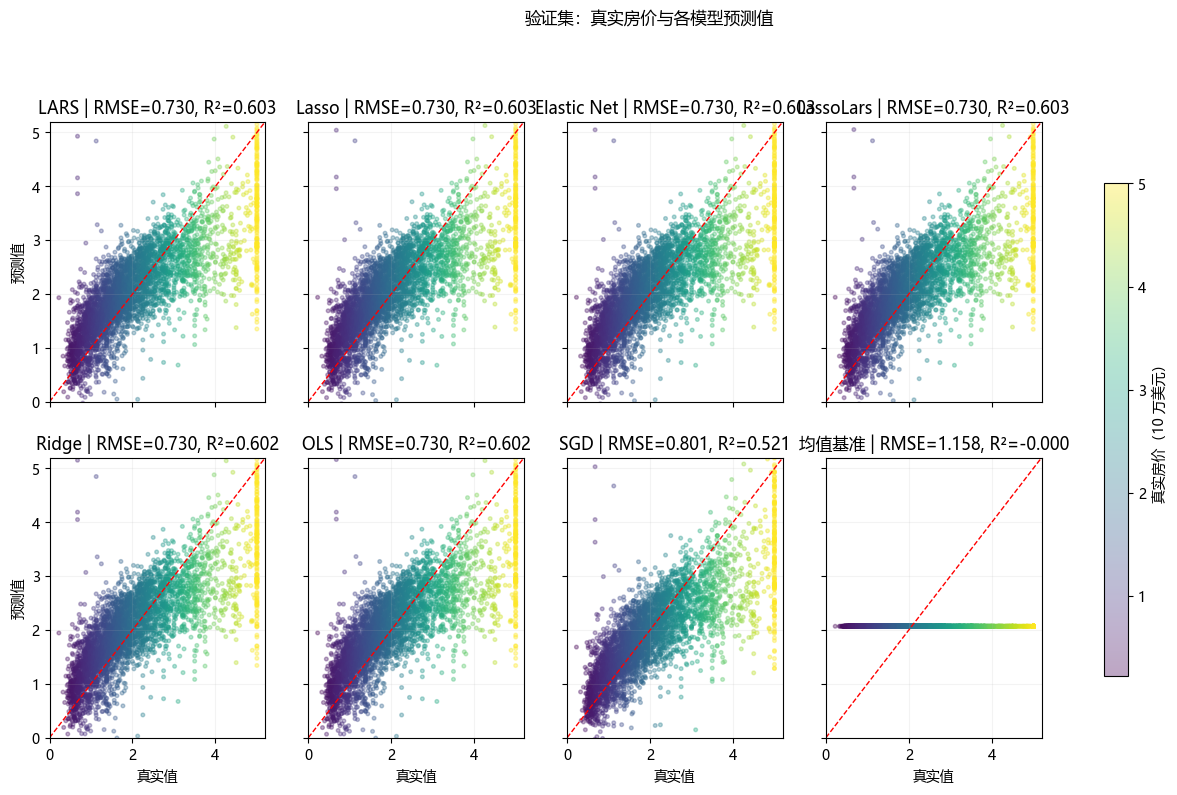

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for ax, row in zip(axes.ravel(), validation_results.itertuples(index=False)):
    name = row[0]
    pred = fitted_train[name].predict(X_val)
    pts = ax.scatter(y_val, pred, c=y_val, cmap="viridis", s=7, alpha=0.35)
    ax.plot([0, 5.2], [0, 5.2], "r--", linewidth=1)
    ax.set_title(f"{name} | RMSE={row[3]:.3f}, R²={row[5]:.3f}")
    ax.set_xlim(0, 5.2)
    ax.set_ylim(0, 5.2)
    ax.grid(alpha=0.15)
for ax in axes[-1, :]: ax.set_xlabel("真实值")
for ax in axes[:, 0]: ax.set_ylabel("预测值")
fig.colorbar(pts, ax=axes.ravel().tolist(), label="真实房价（10 万美元）", shrink=0.8)
fig.suptitle("验证集：真实房价与各模型预测值", y=1.02)
plt.show()

## 五、选模、重拟合与最终测试

在验证集 RMSE 最低的模型族中选出最终方案。随后固定它在训练集交叉验证中找到的参数，用训练集和验证集合并的数据重新拟合，最后才评估从未参与选模的测试集。这样既利用了验证集做模型族比较，也避免把测试集误当成第二个验证集。

测试 RMSE、MAE、$R^2$ 是对这一次划分的最终报告。它们不应再用于反复修改参数；若要估计指标波动，应使用重复交叉验证或 bootstrap，而不是不停重抽测试集直到结果变好。

In [7]:
selected_name = validation_results.iloc[0]["模型"]
selected_params = searches[selected_name].best_params_ if selected_name in searches else {}
final_model = clone(fitted_train[selected_name])
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])
final_model.fit(X_train_final, y_train_final)
y_test_pred = final_model.predict(X_test)

test_metrics = pd.DataFrame([{
    "最终模型": selected_name,
    "测试 RMSE": mean_squared_error(y_test, y_test_pred) ** 0.5,
    "测试 MAE": mean_absolute_error(y_test, y_test_pred),
    "测试 R²": r2_score(y_test, y_test_pred),
    "训练 + 验证样本数": len(X_train_final),
    "最优参数": selected_params or "无（基准模型）",
}])
display(test_metrics.round(4))
print("依据验证 RMSE 选出的模型：", selected_name)

,最终模型,测试 RMSE,测试 MAE,测试 R²,训练 + 验证样本数,最优参数
0,LARS,0.7428,0.5364,0.582,16512,{'model__n_nonzero_coefs': 7}


依据验证 RMSE 选出的模型： LARS


### 5.1 测试集残差诊断与线性系数

测试散点图展示独立样本的预测精度；残差对预测值图帮助发现系统性偏差。若最终模型是线性模型，下表列出标准化尺度下的系数，系数绝对值可比较线性预测量中相对影响大小，但高度相关的特征会使单个系数不稳定。

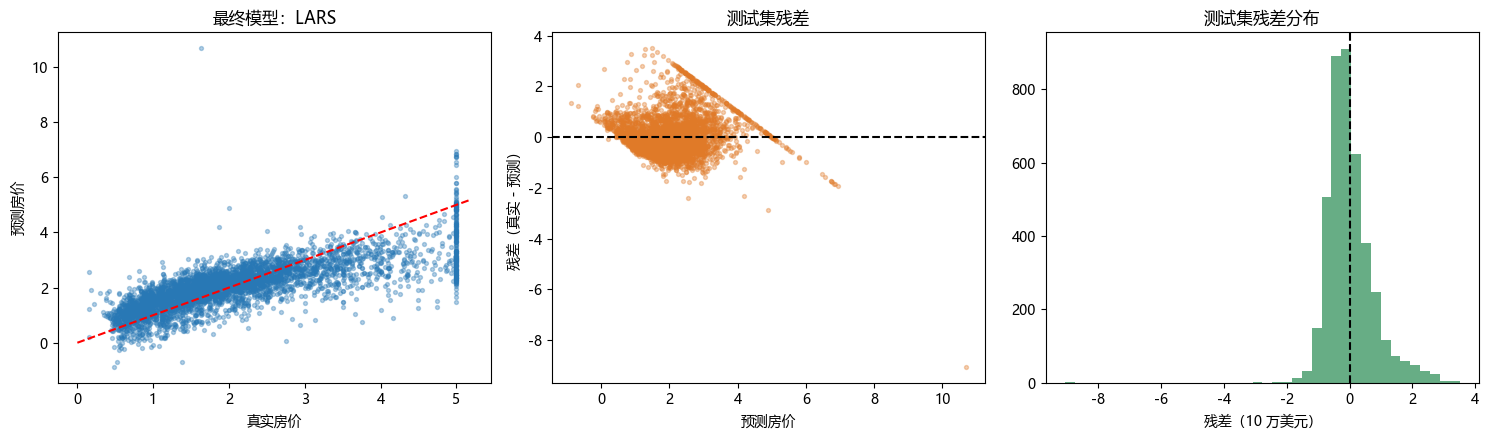

,特征,标准化系数,绝对系数
6,Latitude,-0.8992,0.8992
7,Longitude,-0.8720,0.8720
0,MedInc,0.8433,0.8433
3,AveBedrms,0.2888,0.2888
2,AveRooms,-0.2526,0.2526
1,HouseAge,0.1220,0.1220
5,AveOccup,-0.0295,0.0295
4,Population,0.0000,0.0000


In [8]:
residuals = y_test.to_numpy() - y_test_pred
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(y_test, y_test_pred, s=8, alpha=0.35, color="#2878B5")
axes[0].plot([0, 5.2], [0, 5.2], "r--")
axes[0].set(xlabel="真实房价", ylabel="预测房价", title=f"最终模型：{selected_name}")
axes[1].scatter(y_test_pred, residuals, s=8, alpha=0.35, color="#E07A28")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="预测房价", ylabel="残差（真实 - 预测）", title="测试集残差")
axes[2].hist(residuals, bins=40, color="#4C9F70", alpha=0.85)
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set(xlabel="残差（10 万美元）", title="测试集残差分布")
plt.tight_layout()
plt.show()

model_step = final_model.named_steps["model"]
if hasattr(model_step, "coef_"):
    coef = np.ravel(model_step.coef_)
    coefficient_table = pd.DataFrame({"特征": X.columns, "标准化系数": coef})
    coefficient_table["绝对系数"] = coefficient_table["标准化系数"].abs()
    display(coefficient_table.sort_values("绝对系数", ascending=False).round(4))
else:
    print("最终估计器没有线性系数表；可从上方验证集误差和残差图解释其预测表现。")

## 六、结果讨论与局限

从验证表判断正则化模型是否改善 OLS，而不是只比较训练误差。若训练误差明显较低但验证误差变高，模型复杂度可能过大；若 Ridge/Lasso 与 OLS 接近，说明当前特征下收缩主要提高稳定性，预测精度增益有限。SGD 的结果还受学习率和停止条件影响，须结合其交叉验证曲线看是否充分收敛。

加州房价数据有明显空间结构，且普查街区是聚合单位。随机划分可能让相邻区域同时进入训练和测试，从而高估模型迁移到全新地区的表现；更严格的空间泛化评估应按地理区域分组留出。目标上限截断、遗漏的房屋和社区因素及 1990 年数据时效性也限制了结论。